In [2]:
import h5py
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path

In [4]:
test_path = Path("/home/athira/Downloads")
test_path_h5 = test_path / "DTS_Data.h5"
filename = test_path_h5

In [5]:
def print_structure(name, obj):
    """Callback function to print the layout of groups and datasets."""
    if isinstance(obj, h5py.Group):
        print(f"📁 Group: {name}")
    elif isinstance(obj, h5py.Dataset):
        print(f"  📄 Dataset: {name} | Shape: {obj.shape} | Type: {obj.dtype}")

# Open the file in read-only mode
with h5py.File(filename, "r") as f:
    print(f"=== File Structure for: {filename} ===")
    f.visititems(print_structure)

=== File Structure for: /home/athira/Downloads/DTS_Data.h5 ===
📁 Group: DTS_Data
📁 Group: DTS_Data/Angle_Tomas
📁 Group: DTS_Data/Angle_Tomas/0_0
  📄 Dataset: DTS_Data/Angle_Tomas/0_0/value | Shape: (79427,) | Type: float64
📁 Group: DTS_Data/Angle_Tomas/0_1
  📄 Dataset: DTS_Data/Angle_Tomas/0_1/value | Shape: (88863,) | Type: float64
📁 Group: DTS_Data/Angle_Tomas/0_10
  📄 Dataset: DTS_Data/Angle_Tomas/0_10/value | Shape: (79428,) | Type: float64
📁 Group: DTS_Data/Angle_Tomas/0_11
  📄 Dataset: DTS_Data/Angle_Tomas/0_11/value | Shape: (79300,) | Type: float64
📁 Group: DTS_Data/Angle_Tomas/0_12
  📄 Dataset: DTS_Data/Angle_Tomas/0_12/value | Shape: (80075,) | Type: float64
📁 Group: DTS_Data/Angle_Tomas/0_13
  📄 Dataset: DTS_Data/Angle_Tomas/0_13/value | Shape: (79829,) | Type: float64
📁 Group: DTS_Data/Angle_Tomas/0_14
  📄 Dataset: DTS_Data/Angle_Tomas/0_14/value | Shape: (79196,) | Type: float64
📁 Group: DTS_Data/Angle_Tomas/0_15
  📄 Dataset: DTS_Data/Angle_Tomas/0_15/value | Shape: (81205

In [6]:
with h5py.File(filename, "r") as f:
    print("=== File-Level Metadata / Attributes ===")
    for key, val in f.attrs.items():
        print(f"  {key}: {val}")

    # Inspect metadata on a specific dataset
    dataset_name = "path/to/dataset"  # Replace with a dataset found in Step 2
    if dataset_name in f:
        print(f"\n=== Attributes for {dataset_name} ===")
        for key, val in f[dataset_name].attrs.items():
            print(f"  {key}: {val}")

=== File-Level Metadata / Attributes ===
  branch: python_from_rawtracking
  format: DTS_Data


In [11]:
import h5py
import numpy as np
import pandas as pd

file_path = "/home/athira/Downloads/DTS_Data.h5"

saccade_data = {}

with h5py.File(file_path, "r") as h5f:
    # 1. Inspect available groups in DTS_Data
    root_group = h5f["DTS_Data"]

    has_raw = "saccadePeak" in root_group
    has_true = "saccadePeak_true" in root_group

    # Collect all unique fly/trial keys (e.g., '0_0', '0_1', '0_12')
    all_fly_keys = set()
    if has_raw:
        all_fly_keys.update(root_group["saccadePeak"].keys())
    if has_true:
        all_fly_keys.update(root_group["saccadePeak_true"].keys())

    summary_rows = []

    for key in sorted(all_fly_keys, key=lambda x: int(x.split("_")[-1])):
        fly_id = int(key.split("_")[-1])

        # Extract candidate saccade frame indices
        raw_peaks = np.array([])
        if has_raw and f"saccadePeak/{key}/value" in root_group:
            raw_peaks = root_group[f"saccadePeak/{key}/value"][:]

        # Extract true/filtered saccade frame indices
        true_peaks = np.array([])
        if has_true and f"saccadePeak_true/{key}/value" in root_group:
            true_peaks = root_group[f"saccadePeak_true/{key}/value"][:]

        # Store raw arrays in dictionary
        saccade_data[f"fly_{fly_id}"] = {
            "saccadePeak_raw_frames": raw_peaks,
            "saccadePeak_true_frames": true_peaks,
        }

        # Calculate acceptance ratio
        n_raw = len(raw_peaks)
        n_true = len(true_peaks)
        acceptance_rate = (n_true / n_raw * 100) if n_raw > 0 else 0.0

        summary_rows.append(
            {
                "fly_id": fly_id,
                "h5_key": key,
                "n_candidate_saccades": n_raw,
                "n_true_saccades": n_true,
                "filter_pass_rate_pct": round(acceptance_rate, 2),
            }
        )

# Build a summary DataFrame
df_saccade_summary = pd.DataFrame(summary_rows)
print("=== Saccade Summary Across Flies ===")
print(df_saccade_summary.to_string(index=False))

=== Saccade Summary Across Flies ===
 fly_id h5_key  n_candidate_saccades  n_true_saccades  filter_pass_rate_pct
      0    0_0                   674              232                 34.42
      1    0_1                   528              247                 46.78
      2    0_2                  1116              428                 38.35
      3    0_3                   741              247                 33.33
      4    0_4                   681              283                 41.56
      5    0_5                   752              259                 34.44
      6    0_6                   547              168                 30.71
      7    0_7                   644              210                 32.61
      8    0_8                   805              343                 42.61
      9    0_9                   977              364                 37.26
     10   0_10                   890              383                 43.03
     11   0_11                   845              2

In [12]:
# Access frame indices for fly 12
fly_12_true_frames = saccade_data["fly_12"]["saccadePeak_true_frames"]
print(f"Fly 12 executed true saccades at frames:\n{fly_12_true_frames[:10]}...")

# Example: Convert frame indices to time (seconds) assuming 60 FPS
fps = 60.0
fly_12_saccade_times_sec = fly_12_true_frames / fps

Fly 12 executed true saccades at frames:
[  37   85  137  208  260  847 1071 1188 1242 1275]...


In [13]:
import h5py

file_path = "/home/athira/Downloads/DTS_Data.h5"

with h5py.File(file_path, "r") as h5f:
    # Access the main DTS_Data container
    dts_group = h5f["DTS_Data"]

    print("=== Direct Group Names inside 'DTS_Data' ===")
    for name, obj in dts_group.items():
        if isinstance(obj, h5py.Group):
            print(name)

=== Direct Group Names inside 'DTS_Data' ===
Angle_Tomas
Frames
Frames_L
VrBouts
VrBouts500ms
XBouts
XBouts500ms
X_Tomas
YBouts
YBouts500ms
Y_Tomas
analysis_params
andDspk
angD
angDP
auxP
diagnostic_example
forwardVel
idxFWBouts
idxFWBouts500ms
indsSpksFlies
lenDP
pks
pksP
pksP_idx
rotVel
saccadeLeft
saccadeLeft_true
saccadePeak
saccadePeak_true
saccadeRight
saccadeRight_true
sideVel
transVel
walldist


In [34]:
import h5py
import numpy as np
import pandas as pd

# File paths
h5_path = "/home/athira/CF/PhD/Data/run_Gr43a_Gal4_ATR_20260927_224054/DTS_Data.h5"
csv_path = "/home/athira/CF/PhD/Data/run_Gr43a_Gal4_ATR_20260927_224054/behavior_metrics_by_fly.csv"  # Update with your actual CSV path

# 1. Load mapping metadata (Expected columns: 'fly_index' or 'h5_key', 'genotype', 'filepath', etc.)
df_meta = pd.read_csv(csv_path)

# Normalize fly_key format (e.g., ensuring "0_14" matches the HDF5 structure)
if "h5_key" not in df_meta.columns and "fly_index" in df_meta.columns:
    df_meta["h5_key"] = df_meta["fly_index"].apply(lambda x: f"0_{x}")


def extract_fly_data(h5_file, key):
    """Extracts trajectory, orientation, and saccade events for a given fly key."""
    root = h5_file["DTS_Data"]

    data = {}

    # Extract Saccade Peak Frame Indices
    if f"saccadePeak/{key}/value" in root:
        data["saccade_raw_frames"] = root[f"saccadePeak/{key}/value"][:]
    else:
        data["saccade_raw_frames"] = np.array([])

    if f"saccadePeak_true/{key}/value" in root:
        data["saccade_true_frames"] = root[f"saccadePeak_true/{key}/value"][:]
    else:
        data["saccade_true_frames"] = np.array([])

    # Extract Body/Head Angles if available
    if f"Angle_Tomas/{key}/value" in root:
        data["angle"] = root[f"Angle_Tomas/{key}/value"][:]

    # Extract Velocities / Trajectory if present in HDF5 root
    for metric in ["X_Tomas", "Y_Tomas", "forwardVel", "sideVel", "rotVel"]:
        if f"{metric}/{key}/value" in root:
            data[metric] = root[f"{metric}/{key}/value"][:]

    return data



In [35]:

# 2. Extract and compile data across all flies
compiled_dataset = {}

with h5py.File(h5_path, "r") as h5f:
    for idx, row in df_meta.iterrows():
        key = f'{str(row["protocol_idx"])}_{str(row["fly_idx"])}'

        # Pull extracted arrays from HDF5
        fly_data = extract_fly_data(h5f, key)

        # Attach metadata (e.g., Gr43a vs Gr5a genotype)
        fly_data["metadata"] = row.to_dict()

        compiled_dataset[key] = fly_data

print(f"Successfully loaded and aligned {len(compiled_dataset)} flies.")

Successfully loaded and aligned 12 flies.


In [36]:
compiled_dataset['0_0']

{'saccade_raw_frames': array([   57,   506,   531,   613,   767,   791,   837,   868,   877,
          914,   955,  1207,  1224,  1233,  1271,  1278,  1360,  1403,
         1628,  1641,  1678,  1780,  1873,  1910,  1923,  1931,  2017,
         2289,  2329,  2348,  2517,  2525,  2565,  2580,  2620,  2644,
         2734,  2766,  2820,  2829,  2860,  2890,  2910,  2932,  2981,
         3081,  3104,  3125,  3197,  3209,  3224,  3232,  3241,  3257,
         3807,  4093,  4108,  4117,  4226,  4234,  4239,  4252,  4256,
         4331,  4474,  4592,  4636,  4793,  4800,  4848,  4902,  4920,
         5030,  5055,  5205,  5222,  5363,  5456,  5517,  5749,  6314,
         6420,  6426,  6457,  6478,  6486,  6509,  6534,  6719,  6791,
         6843,  6862,  6873,  6887,  6940,  6993,  7040,  7096,  7113,
         7225,  7276,  7332,  7420,  7525,  7529,  7546,  7622,  7626,
         7632,  8325,  8551,  8673,  8676,  8757,  8777,  8787,  8798,
         8806,  8840,  8857,  8950,  8990,  9138,  9154

In [37]:
def compute_dts_bias_for_fly(
    fly_data, pre_window_frames=30, saccade_window_frames=10
):
    """Calculates DTS anticorrelation score for a single fly's true saccades."""
    true_saccades = fly_data.get("saccade_true_frames", [])
    angles = fly_data.get("angle", None)

    if len(true_saccades) == 0 or angles is None:
        return []

    dts_events = []

    for peak_idx in true_saccades:
        # Prevent boundary errors
        if (
            peak_idx < pre_window_frames
            or peak_idx + saccade_window_frames >= len(angles)
        ):
            continue

        # 1. Preceding Drift Bias (Mean Angular Change prior to saccade)
        pre_drift = angles[peak_idx] - angles[peak_idx - pre_window_frames]

        # 2. Saccade Turn Direction & Amplitude
        saccade_turn = (
            angles[peak_idx + saccade_window_frames] - angles[peak_idx]
        )

        # Unwrap angles to handle -pi to +pi wrap-around
        pre_drift = (pre_drift + np.pi) % (2 * np.pi) - np.pi
        saccade_turn = (saccade_turn + np.pi) % (2 * np.pi) - np.pi

        # 3. Check for Anti-Correlation (Biased DTS)
        # If pre_drift and saccade_turn have OPPOSITE signs, the product is NEGATIVE (Corrective)
        is_anti_correlated = (pre_drift * saccade_turn) < 0

        dts_events.append(
            {
                "saccade_frame": peak_idx,
                "pre_drift_rad": pre_drift,
                "saccade_turn_rad": saccade_turn,
                "is_corrective_dts": is_anti_correlated,
            }
        )

    return pd.DataFrame(dts_events)

In [39]:
results = []

for key, fly_data in compiled_dataset.items():
    genotype = fly_data["metadata"].get("genotype", "Unknown")

    

    df_dts = compute_dts_bias_for_fly(fly_data)
    print(len(df_dts))

    try:
        bias_ratio = df_dts["is_corrective_dts"].mean() * 100
        n_saccades = len(df_dts)

        results.append(
            {
                "h5_key": key,
                "genotype": genotype,
                "n_true_saccades": n_saccades,
                "corrective_dts_pct": round(bias_ratio, None),
            }
        )
    except Exception as e:
        print(e, key)

df_comparison = pd.DataFrame(results)

# Group by Genotype to see the average DTS bias
print("=== DTS Bias Comparison Across Genotypes ===")
summary = df_comparison.groupby("genotype").agg(
    mean_corrective_dts_pct=("corrective_dts_pct", "mean"),
    sem_dts_pct=("corrective_dts_pct", "sem"),
    total_flies=("h5_key", "count"),
    total_saccades=("n_true_saccades", "sum"),
)
print(summary)

140
219
301
492
273
251
22
80
359
529
491
211
=== DTS Bias Comparison Across Genotypes ===
                mean_corrective_dts_pct  sem_dts_pct  total_flies  \
genotype                                                            
Gr43a_Gal4_ATR                50.666667     0.940127           12   

                total_saccades  
genotype                        
Gr43a_Gal4_ATR            3368  


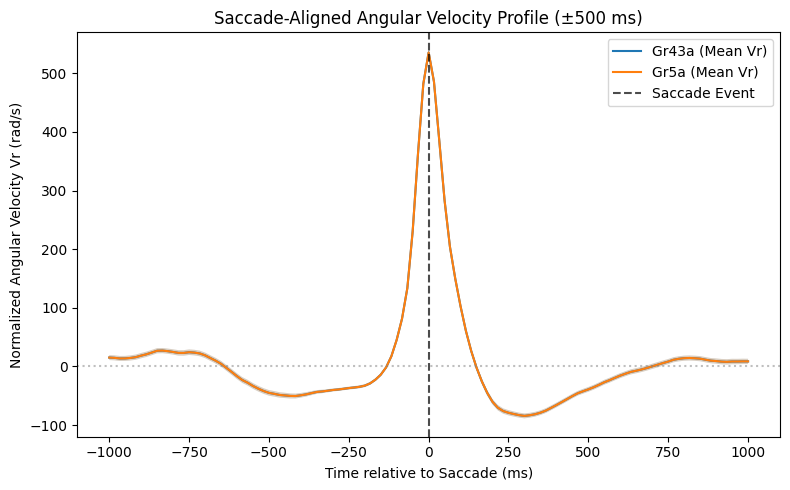

In [48]:
import matplotlib.pyplot as plt
import numpy as np


def extract_aligned_vr(
    fly_data, window_ms=500, fps=60.0, use_onset=False
):
    """Extracts Vr traces sliced around saccade peaks or onsets.

    Parameters:
    - window_ms: Time window in milliseconds (+/- around event)
    - fps: Frame rate of recording
    - use_onset: If True, uses saccade onset; if False, uses saccade peak
    """
    saccades = fly_data.get("saccade_true_frames", [])
    vr = fly_data.get("rotVel", None)

    if len(saccades) == 0 or vr is None:
        return None, None

    half_window = int((window_ms / 1000.0) * fps)
    time_vector = np.linspace(-window_ms, window_ms, 2 * half_window + 1)

    aligned_traces = []

    for event_idx in saccades:
        # If aligning to onset, shift back by estimated rise time (~3-5 frames / 50-80ms)
        align_idx = event_idx - 4 if use_onset else event_idx

        # Ensure window stays within array bounds
        if align_idx - half_window < 0 or align_idx + half_window >= len(vr):
            continue

        trace = vr[align_idx - half_window : align_idx + half_window + 1]

        # Normalization trick: align saccade turn direction so all peaks go POSITIVE
        # This keeps pre-saccade drift signs relative to the main turn!
        saccade_dir = np.sign(vr[event_idx])
        if saccade_dir < 0:
            trace = -trace  # Flip left turns so all peak turns point up

        aligned_traces.append(trace)

    if len(aligned_traces) == 0:
        
        return None, None

    return time_vector, np.array(aligned_traces)


# ==========================================
# Plotting Comparison across Genotypes
# ==========================================
plt.figure(figsize=(8, 5))

for genotype_name in ["Gr43a", "Gr5a"]:
    all_genotype_traces = []

    for key, fly_data in compiled_dataset.items():
        
        time_vec, traces = extract_aligned_vr(
            fly_data, window_ms=1000, fps=60.0
        )
        
        if traces is not None:
            all_genotype_traces.append(traces)

    if len(all_genotype_traces) > 0:
        stacked_traces = np.vstack(all_genotype_traces)
        mean_trace = np.mean(stacked_traces, axis=0)
        sem_trace = np.std(stacked_traces, axis=0) / np.sqrt(
            len(stacked_traces)
        )

        plt.plot(time_vec, mean_trace, label=f"{genotype_name} (Mean Vr)")
        plt.fill_between(
            time_vec,
            mean_trace - sem_trace,
            mean_trace + sem_trace,
            alpha=0.2,
        )

plt.axvline(0, color="k", linestyle="--", alpha=0.7, label="Saccade Event")
plt.axhline(0, color="gray", linestyle=":", alpha=0.5)
plt.xlabel("Time relative to Saccade (ms)")
plt.ylabel("Normalized Angular Velocity Vr (rad/s)")
plt.title("Saccade-Aligned Angular Velocity Profile (±500 ms)")
plt.legend()
plt.tight_layout()
plt.show()